<a href="https://colab.research.google.com/github/Mikhailo88/MN-Praktychni-K4/blob/main/%D0%9B%D0%A0_6_%D0%9E%D0%BB%D1%8C%D1%85%D0%BE%D0%B2%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:
# Завантаження файлу
uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [3]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


**gender** — стать пацієнта (Female — жіноча, Male — чоловіча).



**age** — вік пацієнта в роках.



**hypertension** — наявність гіпертонії (1 — є, 0 — немає).



**heart_disease** — наявність серцевого захворювання (1 — є, 0 — немає).



**smoking_history** — історія куріння пацієнта (ніколи не курив, курить зараз, курив раніше тощо).



**bmi** — індекс маси тіла, який характеризує співвідношення маси тіла до зросту.



**HbA1c_level** — рівень глікованого гемоглобіну, що відображає середній рівень глюкози в крові за останні 2–3 місяці.



**blood_glucose_level** — рівень глюкози в крові пацієнта.



**diabetes** — цільова ознака, яка показує наявність діабету (1 — є, 0 — немає).

Вивести інформацію про датасет

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [5]:
df.value_counts("gender")

,count
gender,
Female,58552
Male,41430
Other,18


In [6]:
df.value_counts("smoking_history")

,count
smoking_history,
No Info,35816
never,35095
former,9352
current,9286
not current,6447
ever,4004


In [7]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести типи даних

In [8]:
df.dtypes

,0
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Дослідити цільову змінну: перевірити баланс класів

In [9]:
df['diabetes'].value_counts()

,count
diabetes,
0,91500
1,8500


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [10]:
df.isnull().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
smoking_history,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
diabetes,0


Наявність дублікатів


In [11]:
df.duplicated().sum()

np.int64(3854)

Видалити дублікати

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99994,Female,36.0,0,0,No Info,24.60,4.8,145,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Ще раз перевірити баланс цільової змінної

In [14]:
df['diabetes'].value_counts()

,count
diabetes,
0,87664
1,8482


Побудувати гістограму для цільової змінної


<Axes: xlabel='diabetes', ylabel='count'>

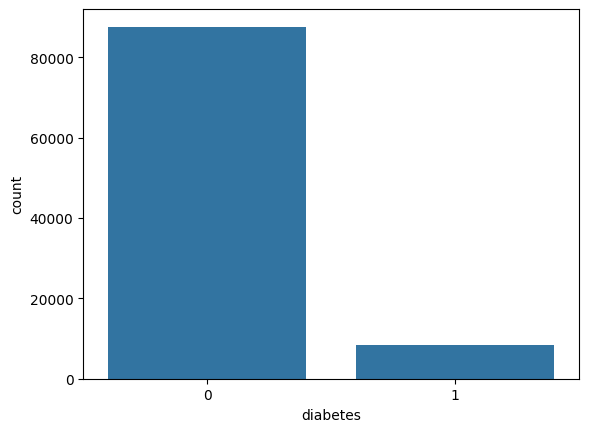

In [15]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [17]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_halving_search_cv
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [18]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

# Розділення на тренувальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (76916, 8) Test: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [19]:
cat_cols = ["gender", "smoking_history"]

X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

# Вирівнювання стовпців тестової вибірки за тренувальною
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("Ознак після кодування:", X_train.shape[1])
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Ознак після кодування: 15
X_train: (76916, 15)
X_test: (19230, 15)


In [20]:
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281,0.582675,0.417143,0.000182,0.342022,0.095546,0.041175,0.097197,0.357650,0.066410
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909,0.493121,0.493090,0.013490,0.474390,0.293969,0.198696,0.296228,0.479311,0.248999
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [21]:
train_data = X_train.copy()
train_data["diabetes"] = y_train

correlation_with_target = train_data.corr(numeric_only=True)["diabetes"].drop("diabetes")

print("Кореляція ознак із цільовою змінною diabetes:")
print(correlation_with_target.sort_values(ascending=False))

Кореляція ознак із цільовою змінною diabetes:
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
gender_Female                 -0.040533
smoking_history_No Info       -0.113053
Name: diabetes, dtype: float64


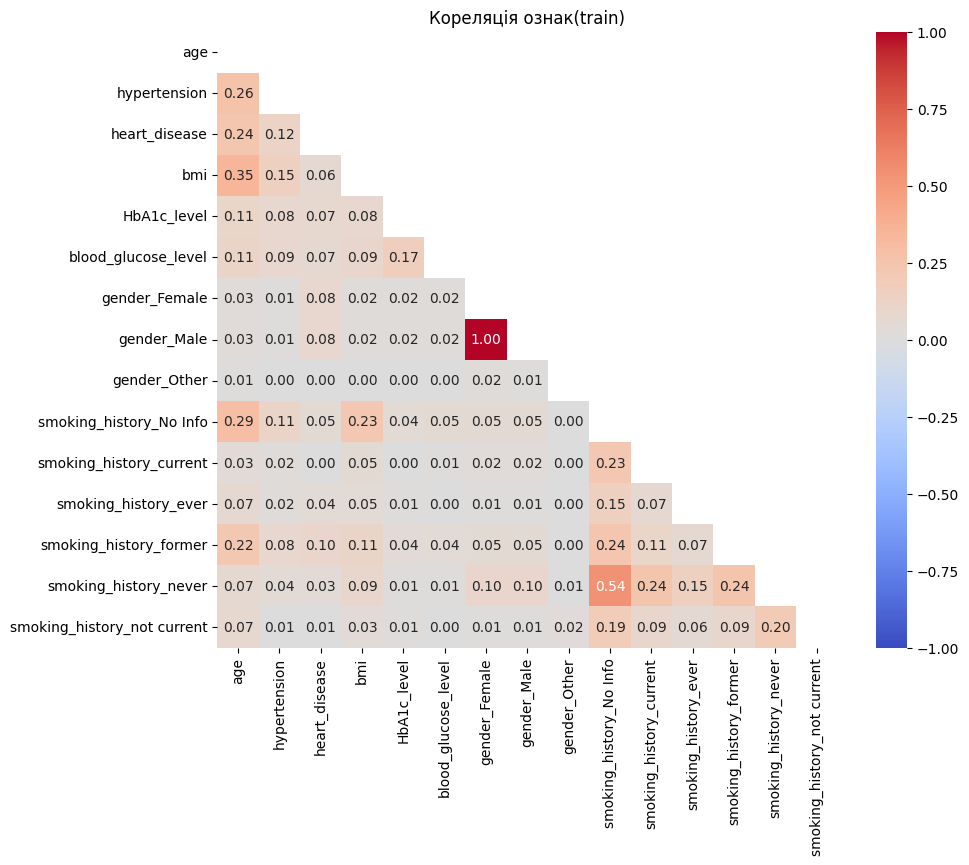

In [22]:
mtx = X_train.corr(numeric_only=True).abs()

plt.figure(figsize=(10,8))
sns.heatmap(mtx, cmap="coolwarm", annot=True, fmt=".2f",
            mask=np.triu(np.ones_like(mtx, dtype=bool)),
            vmin=-1, vmax=1)
plt.title("Кореляція ознак(train)")
plt.tight_layout
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

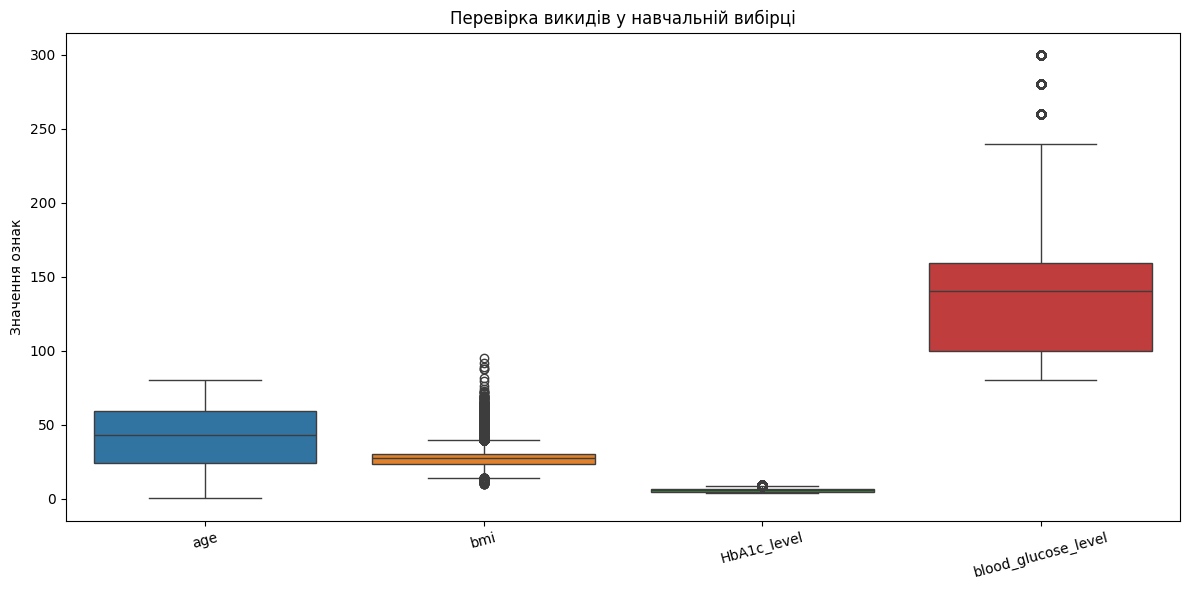

In [23]:
continuous_cols = ["age","bmi","HbA1c_level","blood_glucose_level"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=X_train[continuous_cols])

plt.title("Перевірка викидів у навчальній вибірці")
plt.ylabel("Значення ознак")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [24]:
X_train[continuous_cols].skew()

,0
age,-0.061461
bmi,1.005016
HbA1c_level,-0.055651
blood_glucose_level,0.830778


In [25]:
print("Пропуски в train:", X_train.isna().sum().sum())
print("Пропуски в test:", X_test.isna().sum().sum())

Пропуски в train: 0
Пропуски в test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [26]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Розмір X_train_scaled:", X_train_scaled.shape)
print("Розмір X_test_scaled:", X_test_scaled.shape)

Розмір X_train_scaled: (76916, 15)
Розмір X_test_scaled: (19230, 15)


Балансуємо лише навчальну вибірку за допомогою SMOTE

In [27]:
from collections import Counter
print("До SMOTE:", Counter(y_train))

smote = SMOTE(random_state=42)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train_scaled, y_train
)

print("Після SMOTE:", Counter(y_train_balanced))

До SMOTE: Counter({0: 70130, 1: 6786})
Після SMOTE: Counter({0: 70130, 1: 70130})


Оголошуємо моделі

In [ ]:
param_grids = {
    "LogisticRegression": {
        "C": [0.1, 1, 10],
        "solver": ["liblinear", "lbfgs"]
    },

    "RidgeClassifier": {
        "alpha": [0.1, 1, 10]
    },

    "SGDClassifier": {
        "loss": ["hinge", "log_loss"],
        "penalty": ["l2", "l1", "elasticnet"],
        "alpha": [0.0001, 0.001]
    },

    "SVC": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"]
    }
}

# Перегляд заданих параметрів
for name, params in param_grids.items():
    print(f"\n{name}:")
    print(params)


LogisticRegression:
{'C': [0.1, 1, 10], 'solver': ['liblinear', 'lbfgs']}

RidgeClassifier:
{'alpha': [0.1, 1, 10]}

SGDClassifier:
{'loss': ['hinge', 'log_loss'], 'penalty': ['l2', 'l1', 'elasticnet'], 'alpha': [0.0001, 0.001]}

SVC:
{'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}


Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: LogisticRegression

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



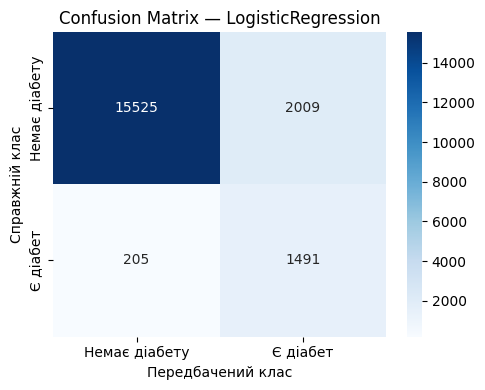


Модель: RidgeClassifier

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



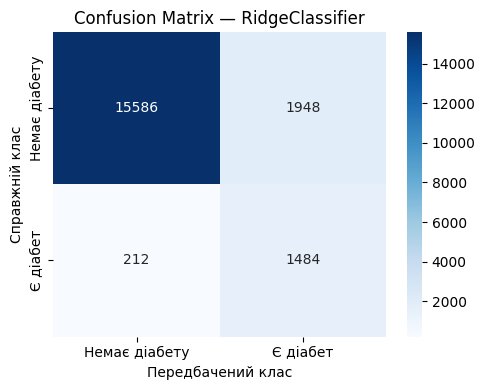


Модель: SGDClassifier

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



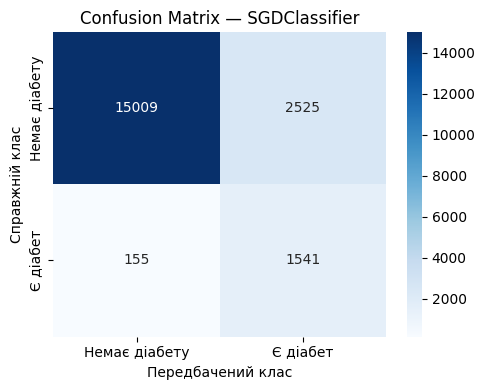


Модель: SVC

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.43      0.91      0.58      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.89      0.76     19230
weighted avg       0.94      0.88      0.90     19230



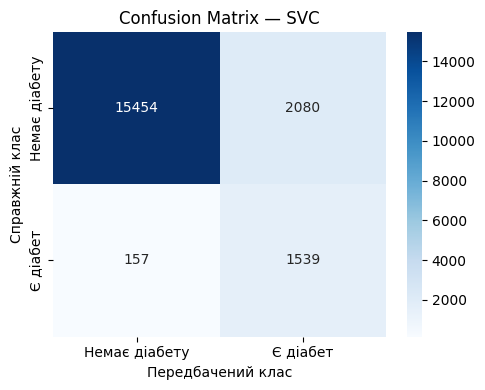

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(
        random_state=42, max_iter=1000
    ),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(
        random_state=42, max_iter=1000
    ),
    "SVC": SVC()
}

# Навчання моделей, прогнозування та оцінювання
from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():
    print(f"\n{'=' * 50}")
    print(f"Модель: {name}")

    # Навчання на збалансованій навчальній вибірці
    model.fit(X_train_balanced, y_train_balanced)

    # Прогноз на тестовій вибірці
    y_pred = model.predict(X_test_scaled)

    # Звіт про якість класифікації
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Матриця помилок
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Немає діабету", "Є діабет"],
        yticklabels=["Немає діабету", "Є діабет"]
    )

    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Передбачений клас")
    plt.ylabel("Справжній клас")
    plt.tight_layout()
    plt.show()

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
models = {
    "LogisticRegression": LogisticRegression(
        random_state=42, max_iter=1000
    ),
    "RidgeClassifier": RidgeClassifier(),
    "SGDClassifier": SGDClassifier(
        random_state=42, max_iter=1000
    ),
    "SVC": SVC()
}

# Сітки параметрів для кожної моделі
param_grids = {
    "LogisticRegression": {
        "model__C": [0.1, 1, 10],
        "model__solver": ["liblinear", "lbfgs"]
    },
    "RidgeClassifier": {
        "model__alpha": [0.1, 1, 10]
    },
    "SGDClassifier": {
        "model__loss": ["hinge", "log_loss"],
        "model__penalty": ["l2", "l1", "elasticnet"],
        "model__alpha": [0.0001, 0.001]
    },
    "SVC": {
        "model__C": [0.1, 1, 10],
        "model__kernel": ["linear", "rbf"]
    }
}

# Словники для збереження результатів
best_models = {}
best_scores = {}

# Пошук оптимальних параметрів для кожної моделі
for name, model in models.items():
    print(f"\n{'=' * 60}")
    print(f"Модель: {name}")

    # Pipeline: масштабування -> SMOTE -> модель
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    # Пошук найкращих параметрів
    search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring="f1",
        min_resources=300,
        factor=3,
        n_jobs=-1,
        random_state=42,
        refit=True
    )

    # Пошук виконується тільки на навчальних даних
    search.fit(X_train, y_train)

    # Збереження найкращої моделі та середнього F1
    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print("Найкращі параметри:", search.best_params_)
    print(f"Середній F1 на крос-валідації: {search.best_score_:.4f}")

    # Оцінювання найкращої моделі на тестовій вибірці
    y_pred = search.best_estimator_.predict(X_test)

    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))


Модель: LogisticRegression
Найкращі параметри: {'model__C': 1, 'model__solver': 'lbfgs'}
Середній F1 на крос-валідації: 0.6098

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230


Модель: RidgeClassifier
Найкращі параметри: {'model__alpha': 10}
Середній F1 на крос-валідації: 0.6516

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230


Модель: SGDClassifier
Найкращі параметри: {'model__alpha': 0.001,

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]

print("Найкраща модель:", best_name)
print(f"Середній F1 на крос-валідації: {best_scores[best_name]:.4f}")

# Порівняння результатів усіх моделей
scores_df = pd.DataFrame({
    "Модель": list(best_scores.keys()),
    "Середній F1 (CV)": list(best_scores.values())
}).sort_values("Середній F1 (CV)", ascending=False)

display(scores_df)

Найкраща модель: RidgeClassifier
Середній F1 на крос-валідації: 0.6516


,Модель,Середній F1 (CV)
1,RidgeClassifier,0.651645
2,SGDClassifier,0.626929
0,LogisticRegression,0.609810
3,SVC,0.589200


In [ ]:
sample_X = X_test.sample(
    n=10,
    random_state=42
)

# Фактичні класи та прогнози найкращої моделі
actual = y_test.loc[sample_X.index]
predicted = best_model.predict(sample_X)

# Створення таблиці результатів
results = pd.DataFrame({
    "Індекс": sample_X.index,
    "Істинний клас": actual.to_numpy(),
    "Передбачений клас": predicted
})

display(results)

,Індекс,Істинний клас,Передбачений клас
0,36061,0,0
1,29824,0,0
2,29668,0,1
3,11816,0,0
4,99242,0,0
5,26718,0,0
6,53059,0,0
7,69294,0,0
8,8912,0,1
9,37072,0,0


**Підсумкові висновки (заповніть самостійно):**

1. Який дисбаланс класів спостерігався? Що показали кореляція та перевірка викидів **на train**?
2. Які моделі дали кращі `F1` і `recall` для класу `diabetes = 1`? Яка модель обрана за кросвалідацією?
3. Які оптимальні гіперпараметри отримано? Які помилки видно в матриці плутанини?
4. Навіщо відкладати тестові дані та виконувати масштабування й SMOTE тільки на train?

**1. Дисбаланс, кореляція та викиди.** Кількість пацієнтів без діабету (17 534) значно перевищувала кількість пацієнтів із діабетом (1 696). Кореляція допомогла оцінити зв’язок між ознаками, а boxplot — виявити потенційні викиди на тренувальній вибірці.

**2. Порівняння моделей.** Найкращий F1-score за крос-валідацією показала RidgeClassifier — 0,6516. Найвищий recall для класу diabetes = 1 показала SVC — 0,89, інші моделі отримали 0,88.

**3. Гіперпараметри та помилки.** Оптимальні параметри RidgeClassifier: alpha = 10. Усі моделі добре виявляли пацієнтів із діабетом за recall, але precision класу 1 становив лише 0,42–0,43, тобто було чимало хибнопозитивних прогнозів.

**4. Розділення даних.** Тестова вибірка забезпечує незалежну оцінку моделі. Масштабування та SMOTE лише на тренувальних фолдах запобігають витоку даних і роблять оцінювання надійнішим.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost**.

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики



In [28]:
%pip install xgboost lightgbm catboost imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 50.2 MB/s  0:00:01


In [34]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score

In [30]:
# Балансування тільки тренувальних даних
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train, y_train
)

# Створення моделей
models_boosting = {
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1
    ),

    "CatBoost": CatBoostClassifier(
        iterations=200,
        depth=6,
        learning_rate=0.1,
        random_seed=42,
        verbose=0,
        allow_writing_files=False
    )
}

results = []


In [31]:
# Навчання та перевірка кожної моделі
for name, model in models_boosting.items():
    print("\n" + "=" * 50)
    print("Модель:", name)

    model.fit(X_train_balanced, y_train_balanced)
    y_pred = model.predict(X_test).ravel().astype(int)

    print("\nКласифікаційний звіт:")
    print(classification_report(y_test, y_pred, zero_division=0))


Модель: XGBoost

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.95      0.70      0.80      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.89     19230
weighted avg       0.97      0.97      0.97     19230


Модель: LightGBM

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.96      0.70      0.81      1696

    accuracy                           0.97     19230
   macro avg       0.96      0.85      0.90     19230
weighted avg       0.97      0.97      0.97     19230


Модель: CatBoost

Класифікаційний звіт:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98     17534
           1       0.96      0.69      0.81      1696

    accuracy                           0.97     19230
   mac

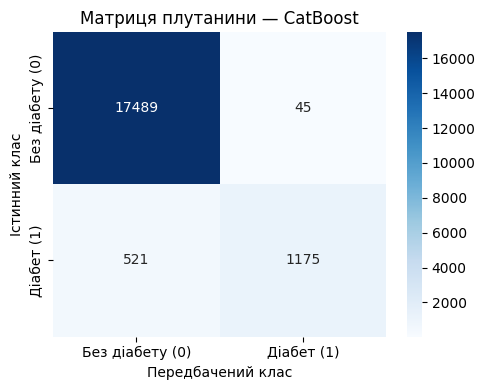

In [32]:
# Матриця плутанини
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Без діабету (0)", "Діабет (1)"],
    yticklabels=["Без діабету (0)", "Діабет (1)"]
)
plt.title(f"Матриця плутанини — {name}")
plt.xlabel("Передбачений клас")
plt.ylabel("Істинний клас")
plt.tight_layout()
plt.show()

In [35]:
 # Збереження метрик для порівняння
results.append({
    "Модель": name,
    "F1 для класу 1": f1_score(y_test, y_pred),
    "Recall для класу 1": recall_score(y_test, y_pred),
    "Accuracy": model.score(X_test, y_test)
})

# Порівняння моделей
results_df = pd.DataFrame(results).sort_values(
    "F1 для класу 1", ascending=False
)

print("\nПорівняння моделей:")
display(results_df)


Порівняння моделей:


,Модель,F1 для класу 1,Recall для класу 1,Accuracy
0,CatBoost,0.805898,0.692807,0.970567


**Висновки до додаткового завдання:** У результаті реалізації XGBoost, LightGBM та CatBoost усі моделі досягли точності (accuracy) близько 97%. Найкращий F1-score для класу diabetes = 1 показали LightGBM і CatBoost — 0,81, а XGBoost отримав 0,80. Найвищий recall серед цих моделей становив 0,70 у XGBoost і LightGBM. Отже, LightGBM показав найкращий баланс метрик, однак усі моделі пропускають приблизно 30% пацієнтів із діабетом, тому є можливість покращити виявлення позитивного класу.